# Pipeline de limpeza e tratamento dos dados de sensores

Este notebook documenta e executa um fluxo reproduzível para `dados_sensores_vulcantech.csv`. O CSV em `data/raw/` é somente leitura; todas as transformações são feitas numa cópia em memória e os resultados são gravados em `data/processed/`.

As faixas normais, os sentinelas de ruído, as categorias e a semântica do alvo foram conferidos em `docs/Prática tabela.xlsx`, `docs/Projeto Integrador Avançado certoo.pdf` e `docs/idealização`. As faixas descritas são faixas normais de operação e, por si só, não justificam remover valores extremos.

## 1. Ambiente, caminhos e dependências

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import pyarrow
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")

# Procura a raiz a partir do diretório atual ou do local do notebook, sem fixar um cwd.
def localizar_raiz(inicio: Path) -> Path:
    inicio = inicio.resolve()
    candidatos = [inicio, *inicio.parents]
    for candidato in candidatos:
        if (candidato / "data" / "raw" / "dados_sensores_vulcantech.csv").is_file() and (candidato / "notebooks").is_dir():
            return candidato
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto e o CSV original.")

RAIZ = localizar_raiz(Path.cwd())
if not (RAIZ / "notebooks").is_dir():
    RAIZ = localizar_raiz(Path(__file__).parent) if "__file__" in globals() else RAIZ
CAMINHO_ORIGINAL = RAIZ / "data" / "raw" / "dados_sensores_vulcantech.csv"
PASTA_PROCESSADOS = RAIZ / "data" / "processed"
CAMINHO_CSV = PASTA_PROCESSADOS / "dados_sensores_vulcantech_tratados.csv"
CAMINHO_PARQUET = PASTA_PROCESSADOS / "dados_sensores_vulcantech_tratados.parquet"
PASTA_PROCESSADOS.mkdir(parents=True, exist_ok=True)
if not CAMINHO_ORIGINAL.is_file():
    raise FileNotFoundError(f"CSV original não encontrado: {CAMINHO_ORIGINAL}")

print(f"Raiz do projeto: {RAIZ}")
print(f"Entrada preservada: {CAMINHO_ORIGINAL}")
print(f"Saída CSV: {CAMINHO_CSV}")
print(f"Saída Parquet: {CAMINHO_PARQUET}")
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__} | PyArrow {pyarrow.__version__}")

Raiz do projeto: C:\Users\adriel_soares2\Documents\VulcanTech Smart Metals S.A
Entrada preservada: C:\Users\adriel_soares2\Documents\VulcanTech Smart Metals S.A\data\raw\dados_sensores_vulcantech.csv
Saída CSV: C:\Users\adriel_soares2\Documents\VulcanTech Smart Metals S.A\data\processed\dados_sensores_vulcantech_tratados.csv
Saída Parquet: C:\Users\adriel_soares2\Documents\VulcanTech Smart Metals S.A\data\processed\dados_sensores_vulcantech_tratados.parquet
Python 3.14.6 | pandas 3.1.0 | NumPy 2.5.4 | PyArrow 26.0.0


## 2. Leitura e diagnóstico do arquivo original

O diagnóstico abaixo precede qualquer limpeza. A leitura usa vírgula, UTF-8 e as formas vazias padrão como ausências. O timestamp é inicialmente lido como texto para reportar e validar a conversão explicitamente.

In [2]:
try:
    original = pd.read_csv(CAMINHO_ORIGINAL, sep=",", encoding="utf-8", low_memory=False)
except (UnicodeDecodeError, pd.errors.ParserError) as erro:
    raise RuntimeError(f"Falha ao ler o CSV em UTF-8 separado por vírgulas: {erro}") from erro

DIMENSOES_ORIGINAIS = original.shape
print(f"Dimensões: {original.shape[0]:,} linhas × {original.shape[1]} colunas")
print("Colunas:", original.columns.tolist())
display(original.dtypes.rename("tipo importado").to_frame())
print("Amostra inicial:")
display(original.head())
print("Amostra final:")
display(original.tail())

resumo_ausencias = pd.DataFrame({
    "ausentes": original.isna().sum(),
    "percentual": (original.isna().mean() * 100).round(2),
})
display(resumo_ausencias)
print(f"Linhas totalmente duplicadas: {original.duplicated().sum():,}")
categoricas = original.select_dtypes(include=["object", "string"]).columns.tolist()
print("Valores únicos nas colunas categóricas:")
display(pd.DataFrame({c: [original[c].nunique(dropna=False)] for c in categoricas}, index=["quantidade"]).T)
print("Estatísticas descritivas das variáveis numéricas:")
display(original.describe(include=["number"]).T)

ALVO = "tipo_falha" if "tipo_falha" in original.columns else None
if ALVO:
    print("Distribuição do alvo:")
    display(original[ALVO].value_counts(dropna=False).sort_index().rename_axis(ALVO).to_frame("quantidade").assign(percentual=lambda x: 100*x.quantidade/x.quantidade.sum()))

if "timestamp" in original.columns:
    datas_originais = pd.to_datetime(original["timestamp"], errors="coerce")
    print(f"Datas inválidas: {datas_originais.isna().sum():,}")
    print(f"Intervalo: {datas_originais.min()} a {datas_originais.max()}")
    diferencas = datas_originais.sort_values().diff().dropna().dt.total_seconds().div(60)
    print("Frequência global (minutos entre registros consecutivos):")
    display(diferencas.value_counts().sort_index().rename_axis("minutos").to_frame("ocorrências").head(15))

# Confere se há colunas que parecem numéricas, mas foram importadas como texto.
for coluna in categoricas:
    if coluna != "timestamp":
        conversao = pd.to_numeric(original[coluna].astype("string").str.strip(), errors="coerce")
        candidatos = original[coluna].notna().sum()
        convertiveis = conversao.notna().sum()
        if candidatos and convertiveis / candidatos > 0.95:
            print(f"Atenção: {coluna!r} é texto, mas {convertiveis:,}/{candidatos:,} valores parecem numéricos.")

Dimensões: 10,000 linhas × 11 colunas
Colunas: ['timestamp', 'id_celula', 'liga_metalica', 'temperatura_fuso_c', 'vibracao_triaxial_rms_mms', 'torque_fuso_nm', 'vazao_refrigerante_lmin', 'corrente_estator_amp', 'pressao_hidraulica_bar', 'nivel_ruido_db', 'tipo_falha']


,tipo importado
timestamp,str
id_celula,str
liga_metalica,str
temperatura_fuso_c,float64
vibracao_triaxial_rms_mms,float64
torque_fuso_nm,float64
vazao_refrigerante_lmin,float64
corrente_estator_amp,float64
pressao_hidraulica_bar,float64
nivel_ruido_db,float64


Amostra inicial:


,timestamp,id_celula,liga_metalica,temperatura_fuso_c,vibracao_triaxial_rms_mms,torque_fuso_nm,vazao_refrigerante_lmin,corrente_estator_amp,pressao_hidraulica_bar,nivel_ruido_db,tipo_falha
0,2026-10-01 00:00:00,CEL-202,Aco_Carbono_316L,56.040,NaN,95.680,26.310,23.730,168.790,53.960,0
1,2026-10-01 00:05:00,CEL-203,Aco_Carbono_316L,50.760,1.930,118.890,29.970,28.310,144.270,53.430,0
2,2026-10-01 00:10:00,CEL-203,Aco_Carbono_316L,54.950,2.090,96.190,29.160,36.110,159.420,54.230,0
3,2026-10-01 00:15:00,CEL-201,Aco_Carbono_316L,58.180,1.900,101.890,29.310,27.770,162.280,52.930,0
4,2026-10-01 00:20:00,CEL-202,Liga_Titanio_Ti6Al4V,65.810,1.820,132.070,27.210,39.150,147.510,73.670,0


Amostra final:


,timestamp,id_celula,liga_metalica,temperatura_fuso_c,vibracao_triaxial_rms_mms,torque_fuso_nm,vazao_refrigerante_lmin,corrente_estator_amp,pressao_hidraulica_bar,nivel_ruido_db,tipo_falha
9995,2026-11-04 16:55:00,CEL-201,Aco_Carbono_316L,48.420,2.040,127.790,26.260,25.610,160.370,55.060,0
9996,2026-11-04 17:00:00,CEL-203,Liga_Titanio_Ti6Al4V,62.980,2.850,123.480,28.040,36.410,162.130,73.860,0
9997,2026-11-04 17:05:00,CEL-202,Aco_Carbono_316L,48.260,1.900,104.810,26.920,26.010,161.810,54.750,0
9998,2026-11-04 17:10:00,CEL-201,Aco_Carbono_316L,58.970,-99.000,167.060,28.050,50.970,106.330,91.030,3
9999,2026-11-04 17:15:00,CEL-203,Aco_Carbono_316L,44.960,1.710,88.200,28.120,28.190,152.490,53.810,0


... (5 outputs left out)

Distribuição do alvo:


,quantidade,percentual
tipo_falha,,
0,8557,85.570
1,470,4.700
2,509,5.090
3,464,4.640


Datas inválidas: 0
Intervalo: 2026-10-01 00:00:00 a 2026-11-04 17:15:00
Frequência global (minutos entre registros consecutivos):


,ocorrências
minutos,
5.000,9999


## 3. Cópia de trabalho e referência às regras documentadas

Colunas, rótulos e identificadores mantêm seus nomes e valores sem conversões semânticas. A variável `tipo_falha` é categórica apesar de estar codificada como inteiro; seus códigos não serão interpolados nem remapeados.

In [3]:
trabalho = original.copy(deep=True)

# Faixas normais documentadas no PDF do projeto e na planilha de dicionário de dados.
FAIXAS_NORMAIS = {
    "temperatura_fuso_c": (30.0, 75.0),
    "vibracao_triaxial_rms_mms": (0.8, 3.8),
    "torque_fuso_nm": (45.0, 210.0),
    "vazao_refrigerante_lmin": (15.0, 40.0),
    "corrente_estator_amp": (12.0, 55.0),
    "pressao_hidraulica_bar": (110.0, 220.0),
    "nivel_ruido_db": (45.0, 85.0),
}
# Somente estes marcadores foram identificados pela documentação como ruído de aquisição.
SENTINELAS_DOCUMENTADOS = {
    "temperatura_fuso_c": [999.9],
    "vibracao_triaxial_rms_mms": [-99.0],
    "pressao_hidraulica_bar": [-1.0],
}
COLUNAS_ESSENCIAIS = original.columns.tolist()
DIMENSOES_ANTES = trabalho.shape
print("Cópia de trabalho criada; o CSV de origem não seré escrito.")
print("Campos documentados como alvo, identificadores e timestamp permanecem preservados.")

Cópia de trabalho criada; o CSV de origem não seré escrito.
Campos documentados como alvo, identificadores e timestamp permanecem preservados.


## 4. Padronização e sinalização de valores

Os espaços externos em nomes/categorias são removidos apenas se existirem; categorias não são fundidas. O timestamp é convertido com erro explícito. Sentinelas expressamente listados pela documentação são convertidos para ausentes. Outros valores fora das faixas normais são apenas contabilizados: podem indicar condições de falha e não há base para apagá-los ou corrigi-los.

In [4]:
# Preserva significado dos campos; apenas remove espaços periféricos comprovados.
trabalho.columns = trabalho.columns.astype(str).str.strip()
for coluna in trabalho.select_dtypes(include=["object", "string"]).columns:
    if coluna != "timestamp":
        trabalho[coluna] = trabalho[coluna].astype("string").str.strip().replace("", pd.NA)

trabalho["timestamp"] = pd.to_datetime(trabalho["timestamp"], errors="coerce")
if trabalho["timestamp"].isna().any():
    raise ValueError(f"Foram encontradas {trabalho['timestamp'].isna().sum()} datas inválidas; investigar antes de ordenar/interpolar.")

# Numéricas de sensores permanecem numéricas; não converte identificadores nem alvo.
COLUNAS_SENSOR = [c for c in FAIXAS_NORMAIS if c in trabalho.columns]
for coluna in COLUNAS_SENSOR:
    trabalho[coluna] = pd.to_numeric(trabalho[coluna], errors="coerce")

contagem_sentinelas = {}
for coluna, sentinelas in SENTINELAS_DOCUMENTADOS.items():
    if coluna in trabalho.columns:
        mascara = trabalho[coluna].isin(sentinelas)
        contagem_sentinelas[coluna] = int(mascara.sum())
        trabalho.loc[mascara, coluna] = np.nan
print("Sentinelas convertidos em ausentes:", contagem_sentinelas)

# Contabiliza leituras fora da faixa normal, sem removê-las ou substituí-las.
fora_faixa = {}
for coluna, (limite_inferior, limite_superior) in FAIXAS_NORMAIS.items():
    if coluna in trabalho.columns:
        mascara = trabalho[coluna].notna() & ~trabalho[coluna].between(limite_inferior, limite_superior)
        fora_faixa[coluna] = int(mascara.sum())
print("Leituras fora da faixa normal documentada (mantidas):")
display(pd.Series(fora_faixa, name="quantidade").to_frame())

# Diagnóstico por célula e liga, conforme a etapa 1 descrita no projeto.
colunas_ausencia = [c for c in COLUNAS_SENSOR if c in trabalho.columns]
print("Taxa de ausóncia por célula e liga após reconhecer sentinelas:")
resumo_grupos_ausencias = trabalho.groupby(["id_celula", "liga_metalica"], dropna=False)[colunas_ausencia].agg(lambda s: round(s.isna().mean()*100, 2))
display(resumo_grupos_ausencias)

Sentinelas convertidos em ausentes: {'temperatura_fuso_c': 50, 'vibracao_triaxial_rms_mms': 49, 'pressao_hidraulica_bar': 50}
Leituras fora da faixa normal documentada (mantidas):


,quantidade
temperatura_fuso_c,604
vibracao_triaxial_rms_mms,856
torque_fuso_nm,164
vazao_refrigerante_lmin,502
corrente_estator_amp,126
pressao_hidraulica_bar,224
nivel_ruido_db,2026


Taxa de ausóncia por célula e liga após reconhecer sentinelas:


temperatura_fuso_c  vibracao_triaxial_rms_mms  torque_fuso_nm  vazao_refrigerante_lmin  \
id_celula liga_metalica                                                                                                  
CEL-201   Aco_Carbono_316L                   2.930                      3.170           0.000                    2.030   
          Aluminio_7075                      3.820                      2.290           0.000                    1.530   
          Liga_Titanio_Ti6Al4V               2.670                      2.870           0.000                    2.050   
CEL-202   Aco_Carbono_316L                   4.360                      3.110           0.000                    2.570   
          Aluminio_7075                      2.160                      2.670           0.000                    1.650   
          Liga_Titanio_Ti6Al4V               2.350                      2.940           0.000                    1.960   
CEL-203   Aco_Carbono_316L                   3.070                      3.720           0.000                    1.130   
          Aluminio_7075                      1.970                      2.820           0.000                    1.690   
          Liga_Titanio_Ti6Al4V               3.620                      2.210           0.000                    1.010   
CEL-204   Aco_Carbono_316L                   3.100                      3.020           0.000                    3.430   
          Aluminio_7075                      2.250                      3.700           0.000                    2.250   
          Liga_Titanio_Ti6Al4V               2.230                      2.020           0.000                    1.420   

                                corrente_estator_amp  pressao_hidraulica_bar  nivel_ruido_db  
id_celula liga_metalica                                                                       
CEL-201   Aco_Carbono_316L                     0.000                   0.410           0.000  
          Aluminio_7075                        0.000                   0.380           0.000  
          Liga_Titanio_Ti6Al4V                 0.000                   1.030           0.000  
CEL-202   Aco_Carbono_316L                     0.000                   0.700           0.000  
          Aluminio_7075                        0.000                   0.510           0.000  
          Liga_Titanio_Ti6Al4V                 0.000                   0.390           0.000  
CEL-203   Aco_Carbono_316L                     0.000                   0.490           0.000  
          Aluminio_7075                        0.000                   0.560           0.000  
          Liga_Titanio_Ti6Al4V                 0.000                   0.600           0.000  
CEL-204   Aco_Carbono_316L                     0.000                   0.330           0.000  
          Aluminio_7075                        0.000                   0.530           0.000  
          Liga_Titanio_Ti6Al4V                 0.000                   0.200           0.000

## 5. Ausóncias e interpolação temporal conservadora

A documentação do projeto recomenda interpolação temporal por equipamento. A estratégia abaixo interpola apenas valores ausentes em sensores, dentro do mesmo `id_celula` e `liga_metalica`, somente quando há observações válidas antes e depois e o intervalo total entre elas não excede 30 minutos. Esse limite é conservador: cada célula tem intervalo mediano observado de 15 minutos e o fluxo global é de 5 minutos; lacunas mais longas permanecem ausentes. Não há extrapolação nas bordas, preenchimento de identificadores nem da variável-alvo. O alvo e as colunas de rastreabilidade não são usados para inferir leituras.

In [5]:
AUSENCIAS_ANTES = trabalho.isna().sum()
# A linha original é ordenada cronologicamente. A atribuição usa somente o índice original.
trabalho = trabalho.sort_values(["timestamp", "id_celula"], kind="stable").reset_index(drop=True)
MAX_INTERVALO_INTERPOLACAO = pd.Timedelta(minutes=30)
preenchidos_interpolacao = {c: 0 for c in colunas_ausencia}

for (celula, liga), indices in trabalho.groupby(["id_celula", "liga_metalica"], sort=False, dropna=False).groups.items():
    indices = list(indices)
    tempos = trabalho.loc[indices, "timestamp"]
    for coluna in colunas_ausencia:
        serie = trabalho.loc[indices, coluna]
        validos = serie.notna()
        if validos.sum() < 2:
            continue
        pos_validas = np.flatnonzero(validos.to_numpy())
        valores = serie.to_numpy(dtype=float, na_value=np.nan, copy=True)
        tempos_ns = tempos.astype("int64").to_numpy()
        for pos in np.flatnonzero(~validos.to_numpy()):
            anterior = pos_validas[pos_validas < pos]
            posterior = pos_validas[pos_validas > pos]
            if not len(anterior) or not len(posterior):
                continue  # sem extrapolação
            i0, i1 = anterior[-1], posterior[0]
            intervalo = tempos.iloc[i1] - tempos.iloc[i0]
            if intervalo <= pd.Timedelta(0) or intervalo > MAX_INTERVALO_INTERPOLACAO:
                continue  # não atravessa lacunas longas ou timestamps simultâneos
            proporcao = (tempos_ns[pos] - tempos_ns[i0]) / (tempos_ns[i1] - tempos_ns[i0])
            if 0 <= proporcao <= 1:
                valores[pos] = valores[i0] + proporcao * (valores[i1] - valores[i0])
                preenchidos_interpolacao[coluna] += 1
        trabalho.loc[indices, coluna] = valores

AUSENCIAS_DEPOIS = trabalho.isna().sum()
print("Valores preenchidos por interpolação temporal limitada:")
display(pd.Series(preenchidos_interpolacao, name="preenchidos").to_frame())
print("Ausóncias antes e depois:")
display(pd.DataFrame({"antes": AUSENCIAS_ANTES, "depois": AUSENCIAS_DEPOIS, "diferença": AUSENCIAS_ANTES-AUSENCIAS_DEPOIS}))
print("Ausóncias remanescentes são mantidas e documentadas; não houve imputação global.")

Valores preenchidos por interpolação temporal limitada:


,preenchidos
temperatura_fuso_c,33
vibracao_triaxial_rms_mms,36
torque_fuso_nm,0
vazao_refrigerante_lmin,20
corrente_estator_amp,0
pressao_hidraulica_bar,8
nivel_ruido_db,0


Ausóncias antes e depois:


,antes,depois,diferença
timestamp,0,0,0
id_celula,0,0,0
liga_metalica,0,0,0
temperatura_fuso_c,300,267,33
vibracao_triaxial_rms_mms,299,263,36
torque_fuso_nm,0,0,0
vazao_refrigerante_lmin,200,180,20
corrente_estator_amp,0,0,0
pressao_hidraulica_bar,50,42,8
nivel_ruido_db,0,0,0


Ausóncias remanescentes são mantidas e documentadas; não houve imputação global.


## 6. Duplicidades e consistência temporal

Não há uma chave única de leitura definida além da combinação temporal/equipamento que pode ser avaliada. Duplicatas integrais são removidas somente quando existirem, pois repetem todas as colunas. Timestamps iguais não são eliminados. A combinação `timestamp` + `id_celula` é reportada como possível duplicidade de leitura e demanda confirmação operacional antes de qualquer descarte.

In [6]:
duplicadas_completas_antes = int(trabalho.duplicated().sum())
if duplicadas_completas_antes:
    trabalho = trabalho.drop_duplicates().reset_index(drop=True)
print(f"Linhas integralmente duplicadas removidas: {duplicadas_completas_antes}")
print(f"Timestamps repetidos globalmente: {trabalho['timestamp'].duplicated().sum()}")
print(f"Duplicatas por timestamp e célula (investigar, manter): {trabalho.duplicated(['timestamp', 'id_celula']).sum()}")

intervalos_celula = (
    trabalho.sort_values(["id_celula", "timestamp"])
    .groupby("id_celula")["timestamp"].diff().dt.total_seconds().div(60)
)
print("Intervalos observados entre registros da mesma célula (minutos):")
display(intervalos_celula.groupby(trabalho.sort_values(["id_celula", "timestamp"]).id_celula).describe(percentiles=[.5,.9,.95,.99]))
print("A ordem cronológica foi aplicada; nenhuma linha temporal foi criada.")

Linhas integralmente duplicadas removidas: 0
Timestamps repetidos globalmente: 0
Duplicatas por timestamp e célula (investigar, manter): 0
Intervalos observados entre registros da mesma célula (minutos):


,count,mean,std,min,50%,90%,95%,99%,max
id_celula,,,,,,,,,
CEL-201,"2,501.000",19.982,17.399,5.000,15.000,40.000,55.000,85.000,140.000
CEL-202,"2,581.000",19.367,16.973,5.000,15.000,40.000,55.000,85.000,160.000
CEL-203,"2,441.000",20.479,18.091,5.000,15.000,45.000,60.000,80.000,160.000
CEL-204,"2,473.000",20.188,16.772,5.000,15.000,40.000,55.000,80.000,125.000


A ordem cronológica foi aplicada; nenhuma linha temporal foi criada.


## 7. Faixas de operação, outliers e visualização

A tabela abaixo separa leituras fora da faixa normal definida pelo dicionário de dados. Essas faixas são contexto diagnóstico, não limites físicos máximos/mínimos garantidos. Para apoiar a revisão, os boxplots mostram a distribuição sem apagar extremos. A interpolação pode produzir pontos entre duas leituras dentro de um intervalo permitido; sentinelas documentados são contabilizados separadamente.

C:\Users\adriel_soares2\AppData\Local\Temp\ipykernel_13052\3559117978.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eixo.boxplot(trabalho[coluna].dropna(), vert=False, showfliers=True)
C:\Users\adriel_soares2\AppData\Local\Temp\ipykernel_13052\3559117978.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eixo.boxplot(trabalho[coluna].dropna(), vert=False, showfliers=True)
C:\Users\adriel_soares2\AppData\Local\Temp\ipykernel_13052\3559117978.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  eixo.boxplot(trabalho[coluna].dropna(), vert=False, showfliers=True)
C:\Users\adriel_soares2\AppData\Local\Temp\ipykernel_13052\3559117978.py:3: MatplotlibDe

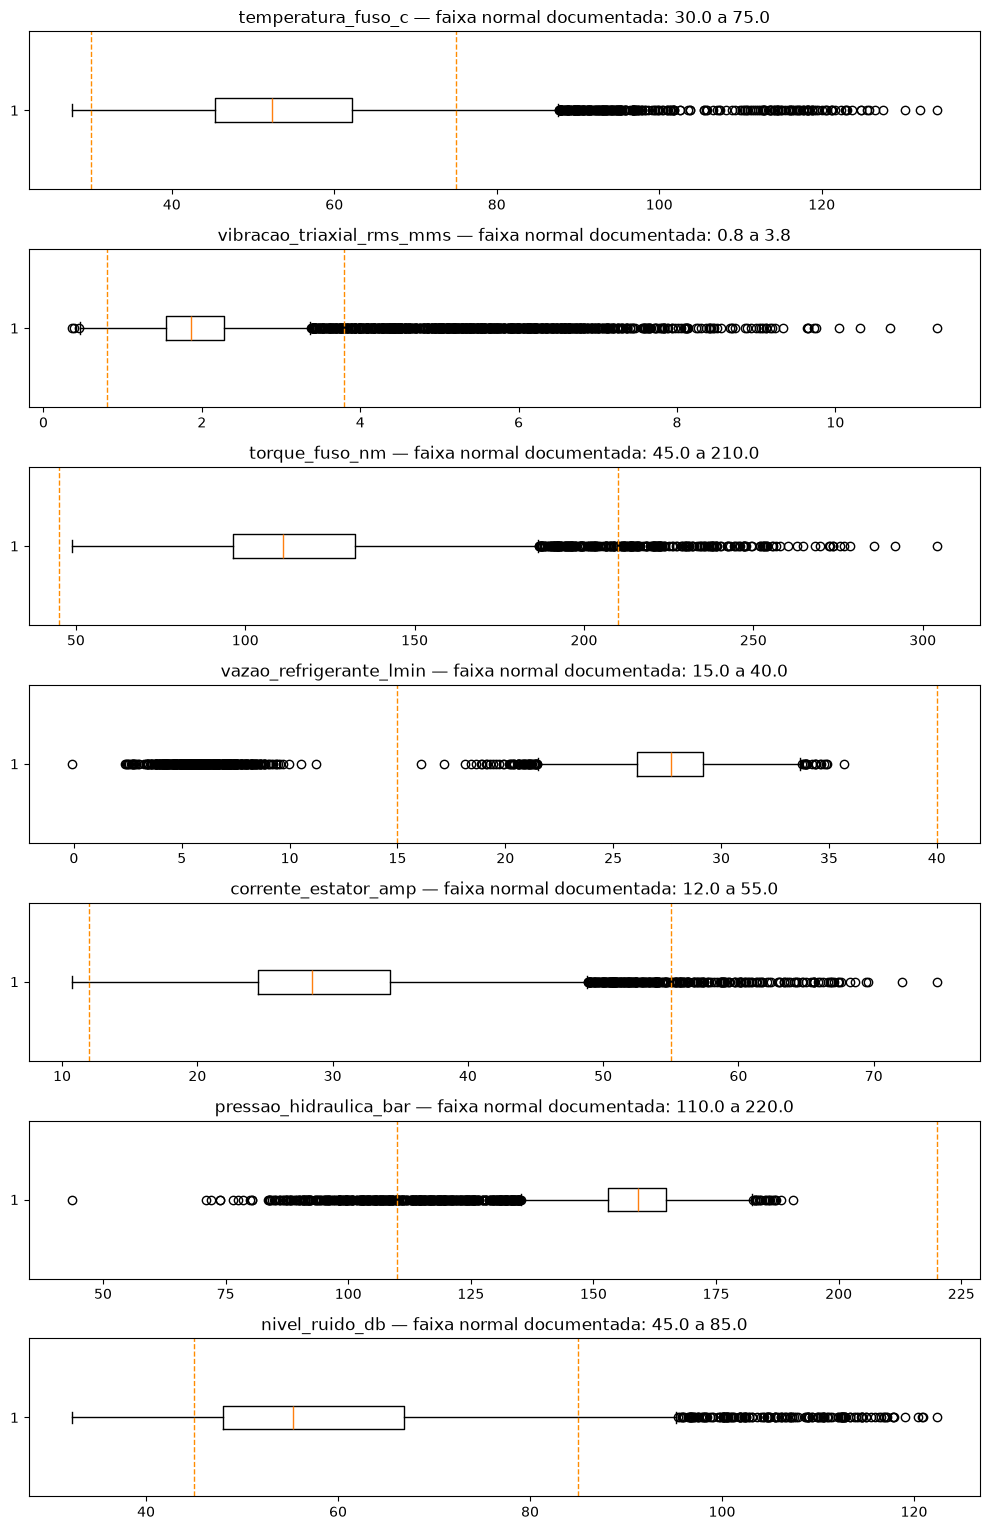

,q1,q3,limite_inferior_iqr,limite_superior_iqr,sinalizados_iqr
sensor,,,,,
temperatura_fuso_c,45.350,62.240,20.015,87.575,292
vibracao_triaxial_rms_mms,1.550,2.280,0.455,3.375,908
torque_fuso_nm,96.297,132.430,42.099,186.629,297
vazao_refrigerante_lmin,26.090,29.150,21.500,33.740,572
corrente_estator_amp,24.468,34.220,9.839,48.849,295
pressao_hidraulica_bar,152.920,164.730,135.205,182.445,528
nivel_ruido_db,48.030,66.910,19.710,95.230,166


Nenhum valor atípico foi removido por IQR ou apenas por estar fora da faixa normal.


In [7]:
fig, eixos = plt.subplots(len(colunas_ausencia), 1, figsize=(10, 2.2*len(colunas_ausencia)))
for eixo, coluna in zip(np.atleast_1d(eixos), colunas_ausencia):
    eixo.boxplot(trabalho[coluna].dropna(), vert=False, showfliers=True)
    inferior, superior = FAIXAS_NORMAIS[coluna]
    eixo.axvline(inferior, color="darkorange", linestyle="--", linewidth=1)
    eixo.axvline(superior, color="darkorange", linestyle="--", linewidth=1)
    eixo.set_title(f"{coluna} — faixa normal documentada: {inferior} a {superior}")
plt.tight_layout()
plt.show()

# IQR serve aqui apenas para sinalização exploratória; não altera os dados.
resumo_iqr = []
for coluna in colunas_ausencia:
    valores = trabalho[coluna].dropna()
    q1, q3 = valores.quantile([.25, .75])
    amplitude = q3-q1
    contagem = int(((valores < q1-1.5*amplitude) | (valores > q3+1.5*amplitude)).sum())
    resumo_iqr.append({"sensor": coluna, "q1": q1, "q3": q3, "limite_inferior_iqr": q1-1.5*amplitude, "limite_superior_iqr": q3+1.5*amplitude, "sinalizados_iqr": contagem})
display(pd.DataFrame(resumo_iqr).set_index("sensor"))
print("Nenhum valor atípico foi removido por IQR ou apenas por estar fora da faixa normal.")

## 8. Preparação para Machine Learning e atributos derivados

O alvo documentado é `tipo_falha` (0 normal, 1 desgaste de ferramenta, 2 falha de refrigeração, 3 desalinhamento/trinca). Rótulos são preservados. O desequilíbrio é reportado; nenhuma reamostragem é aplicada nesta etapa. `timestamp`, `id_celula` e `liga_metalica` devem ser tratados conscientemente no futuro pipeline de treino, com validação temporal/agrupada para evitar vazamento.

Não foram adicionados atributos derivados: a definição de frequência por célula/lote e o objetivo preditivo em tempo real precisam ser definidos antes de calcular estatísticas móveis ou diferenças. A interpolação offline utiliza observações futuras próximas; por isso não deve ser reaproveitada como transformação de inferência em tempo real.

In [8]:
print("Distribuição da variável-alvo antes:")
display(original[ALVO].value_counts().sort_index().rename_axis("código").to_frame("quantidade").assign(percentual=lambda x: (100*x.quantidade/x.quantidade.sum()).round(2)))
print("Distribuição da variável-alvo depois:")
display(trabalho[ALVO].value_counts(dropna=False).sort_index().rename_axis("código").to_frame("quantidade").assign(percentual=lambda x: (100*x.quantidade/x.quantidade.sum()).round(2)))
print("Colunas constantes:", [c for c in trabalho.columns if trabalho[c].nunique(dropna=False) <= 1])
print("Colunas identificadoras/temporais a avaliar fora das features diretas:", [c for c in ["timestamp", "id_celula", "liga_metalica"] if c in trabalho.columns])
assert trabalho[ALVO].value_counts().sort_index().equals(original[ALVO].value_counts().sort_index()), "A distribuição original dos rótulos foi alterada."

Distribuição da variável-alvo antes:


,quantidade,percentual
código,,
0,8557,85.570
1,470,4.700
2,509,5.090
3,464,4.640


Distribuição da variável-alvo depois:


,quantidade,percentual
código,,
0,8557,85.570
1,470,4.700
2,509,5.090
3,464,4.640


Colunas constantes: []
Colunas identificadoras/temporais a avaliar fora das features diretas: ['timestamp', 'id_celula', 'liga_metalica']


## 9. Validações antes da exportação

Antes de exportar, confirmamos a preservação do esquema, das linhas, das chaves de rastreabilidade e da variável-alvo; valores ausentes só podem permanecer em variáveis de sensor já documentadas. Tipos de timestamp e alvo são conferidos.

In [9]:
# Após ordenar, os registros originais são todos mantidos; duplicatas completas, se presentes, seriam justificadas acima.
assert set(COLUNAS_ESSENCIAIS).issubset(trabalho.columns), "Colunas originais essenciais ausentes."
assert len(trabalho) == DIMENSOES_ORIGINAIS[0] - duplicadas_completas_antes, "Contagem de linhas inesperada."
assert trabalho["timestamp"].notna().all(), "Há timestamp inválido."
assert trabalho["id_celula"].notna().all(), "Há identificador de célula ausente."
assert trabalho[ALVO].notna().all(), "Há alvo ausente."
assert set(trabalho[ALVO].dropna().unique()).issubset(set(original[ALVO].dropna().unique())), "O alvo contém rótulos novos."
assert trabalho["timestamp"].is_monotonic_increasing, "Dados não estão em ordem cronológica."
assert trabalho["tipo_falha"].dtype.kind in "iu", "Tipo do alvo deixou de ser inteiro categórico."
assert all(trabalho[c].dtype.kind in "fi" for c in colunas_ausencia), "Algum sensor não permaneceu numérico."

nao_sensores_com_ausencia = [c for c in trabalho.columns if c not in colunas_ausencia and trabalho[c].isna().any()]
assert not nao_sensores_com_ausencia, f"Ausóncias não documentadas em campos essenciais: {nao_sensores_com_ausencia}"
print("Validações pré-exportação aprovadas.")
print(f"Dimensões: original {DIMENSOES_ORIGINAIS} é tratado {trabalho.shape}; diferença de linhas: {len(trabalho)-DIMENSOES_ORIGINAIS[0]:+d}; diferença de colunas: {trabalho.shape[1]-DIMENSOES_ORIGINAIS[1]:+d}")
print(f"Duplicidades completas no tratado: {trabalho.duplicated().sum()}")
print("Tipos antes/depois:")
display(pd.DataFrame({"original": original.dtypes.astype(str), "tratado": trabalho.dtypes.astype(str)}))
print("Estatísticas numéricas do tratado:")
display(trabalho.describe(include=["number"]).T)

Validações pré-exportação aprovadas.
Dimensões: original (10000, 11) é tratado (10000, 11); diferença de linhas: +0; diferença de colunas: +0
Duplicidades completas no tratado: 0
Tipos antes/depois:


,original,tratado
timestamp,str,datetime64[us]
id_celula,str,string
liga_metalica,str,string
temperatura_fuso_c,float64,float64
vibracao_triaxial_rms_mms,float64,float64
torque_fuso_nm,float64,float64
vazao_refrigerante_lmin,float64,float64
corrente_estator_amp,float64,float64
pressao_hidraulica_bar,float64,float64
nivel_ruido_db,float64,float64


Estatísticas numéricas do tratado:


,count,mean,std,min,25%,50%,75%,max
temperatura_fuso_c,"9,733.000",54.852,13.635,27.710,45.350,52.290,62.240,134.160
vibracao_triaxial_rms_mms,"9,737.000",2.182,1.229,0.360,1.550,1.860,2.280,11.280
torque_fuso_nm,"10,000.000",116.772,30.039,48.840,96.297,111.090,132.430,304.150
vazao_refrigerante_lmin,"9,820.000",26.656,5.252,-0.090,26.090,27.660,29.150,35.680
corrente_estator_amp,"10,000.000",29.915,7.955,10.730,24.468,28.500,34.220,74.660
pressao_hidraulica_bar,"9,958.000",157.026,13.685,43.670,152.920,159.005,164.730,190.620
nivel_ruido_db,"10,000.000",57.778,13.151,32.280,48.030,55.280,66.910,122.370
tipo_falha,"10,000.000",0.288,0.765,0.000,0.000,0.000,0.000,3.000


## 10. Exportação CSV e Parquet e validação de recarga

CSV em UTF-8 com vírgula e ausências vazias; Parquet via PyArrow. Os caminhos de saída são distintos do CSV bruto. Após salvar, os arquivos são recarregados e comparados em dimensóes, nomes, chaves, alvo e valores numéricos. O CSV naturalmente reimporta números como tipos numéricos e o timestamp é explicitamente interpretado.

In [10]:
try:
    trabalho.to_csv(CAMINHO_CSV, index=False, encoding="utf-8", na_rep="", date_format="%Y-%m-%d %H:%M:%S")
    trabalho.to_parquet(CAMINHO_PARQUET, index=False, engine="pyarrow")
except Exception as erro:
    raise RuntimeError(f"Falha ao exportar CSV/Parquet para data/processed: {erro}") from erro

rec_csv = pd.read_csv(CAMINHO_CSV, encoding="utf-8", parse_dates=["timestamp"])
rec_parquet = pd.read_parquet(CAMINHO_PARQUET, engine="pyarrow")
for nome, recarregado in [("CSV", rec_csv), ("Parquet", rec_parquet)]:
    assert recarregado.shape == trabalho.shape, f"Dimensões divergentes ao recarregar {nome}."
    assert recarregado.columns.tolist() == trabalho.columns.tolist(), f"Colunas divergentes ao recarregar {nome}."
    assert np.array_equal(recarregado["id_celula"].astype(str).to_numpy(), trabalho["id_celula"].astype(str).to_numpy()), f"Identificadores divergentes em {nome}."
    assert np.array_equal(recarregado["liga_metalica"].astype(str).to_numpy(), trabalho["liga_metalica"].astype(str).to_numpy()), f"Categorias divergentes em {nome}."
    assert recarregado[ALVO].equals(trabalho[ALVO]), f"Alvo divergente em {nome}."
    assert recarregado["timestamp"].equals(trabalho["timestamp"]), f"Timestamp divergente em {nome}."
    for coluna in colunas_ausencia:
        assert np.allclose(recarregado[coluna], trabalho[coluna], equal_nan=True, rtol=1e-12, atol=1e-12), f"Valores divergentes em {coluna} ({nome})."
    print(f"{nome}: recarga validada é {recarregado.shape[0]:,} linhas × {recarregado.shape[1]} colunas")

print("Tipos recarregados do CSV:")
display(rec_csv.dtypes.astype(str).rename("dtype CSV").to_frame())
print("Tipos recarregados do Parquet:")
display(rec_parquet.dtypes.astype(str).rename("dtype Parquet").to_frame())
print(f"Arquivos gravados: {CAMINHO_CSV.stat().st_size:,} bytes (CSV); {CAMINHO_PARQUET.stat().st_size:,} bytes (Parquet).")

CSV: recarga validada é 10,000 linhas × 11 colunas
Parquet: recarga validada é 10,000 linhas × 11 colunas
Tipos recarregados do CSV:


,dtype CSV
timestamp,datetime64[us]
id_celula,str
liga_metalica,str
temperatura_fuso_c,float64
vibracao_triaxial_rms_mms,float64
torque_fuso_nm,float64
vazao_refrigerante_lmin,float64
corrente_estator_amp,float64
pressao_hidraulica_bar,float64
nivel_ruido_db,float64


Tipos recarregados do Parquet:


,dtype Parquet
timestamp,datetime64[us]
id_celula,string
liga_metalica,string
temperatura_fuso_c,float64
vibracao_triaxial_rms_mms,float64
torque_fuso_nm,float64
vazao_refrigerante_lmin,float64
corrente_estator_amp,float64
pressao_hidraulica_bar,float64
nivel_ruido_db,float64


Arquivos gravados: 895,762 bytes (CSV); 299,171 bytes (Parquet).


## 11. Relatório técnico final

Os resultados desta seção são calculados na própria execução, para que o texto reflita o dataset realmente lido e exportado. O conjunto não possui chave de evento confirmada; timestamps repetidos entre células são permitidos. Recomenda-se que a próxima etapa de EDA use cortes por célula, liga e rótulo de falha, e que o treinamento use separação temporal ou por grupos, ajuste de pré-processamento somente no treino e avaliação específica por classe.

In [11]:
classe = trabalho[ALVO].value_counts().sort_index()
linhas_removidas = DIMENSOES_ORIGINAIS[0] - len(trabalho)
fora_faixa_atual = {}
for coluna, (lo, hi) in FAIXAS_NORMAIS.items():
    if coluna in trabalho:
        fora_faixa_atual[coluna] = int((trabalho[coluna].notna() & ~trabalho[coluna].between(lo, hi)).sum())

relatorio = f"""### Resumo baseado nesta execução

- **Origem:** `{CAMINHO_ORIGINAL.relative_to(RAIZ)}`; {DIMENSOES_ORIGINAIS[0]:,} linhas e {DIMENSOES_ORIGINAIS[1]} colunas. CSV separado por vírgulas e lido em UTF-8.
- **Período:** {trabalho.timestamp.min()} a {trabalho.timestamp.max()}. Há {trabalho.timestamp.nunique():,} timestamps distintos; intervalos globais observados de 5 minutos. Por célula, a mediana observada foi de aproximadamente 15 minutos e há lacunas mais longas, portanto não se presume frequência uniforme por máquina.
- **Problemas encontrados:** ausências inicialmente em `temperatura_fuso_c` ({int(original.temperatura_fuso_c.isna().sum())}), `vibracao_triaxial_rms_mms` ({int(original.vibracao_triaxial_rms_mms.isna().sum())}) e `vazao_refrigerante_lmin` ({int(original.vazao_refrigerante_lmin.isna().sum())}); sentinelas documentados detectados: {contagem_sentinelas}.
- **Decisões:** convertidos para ausentes somente os sentinelas explicitamente documentados (`999.9`, `-99.0`, `-1.0`). Interpolados por tempo {sum(preenchidos_interpolacao.values()):,} valores, separados por célula e liga, com observações antes/depois e intervalo máximo de 30 minutos. Ausóncias restantes foram mantidas. Nenhuma classe ou identificador foi imputado.
- **Duplicidades:** {duplicadas_completas_antes:,} linhas totalmente duplicadas removidas; {int(trabalho.duplicated(['timestamp','id_celula']).sum()):,} duplicatas de timestamp e célula permanecem se existentes (investigar antes de decidir). Nenhum registro foi removido apenas por timestamp igual.
- **Faixas e outliers:** fora da faixa normal documentada (valores mantidos): `{fora_faixa_atual}`. Faixa normal não foi tratada como limite físico de descarte. IQR foi usado somente para sinalização exploratória.
- **Alvo:** `tipo_falha` preservado com distribuição `{classe.to_dict()}`. A classe 0 representa operação normal; 1 desgaste; 2 falha de refrigeração; 3 desalinhamento/trinca. Não houve reamostragem nem codificação adicional.
- **Atributos:** nenhum atributo derivado foi criado nesta etapa.
- **Comparação:** {DIMENSOES_ORIGINAIS[0]:,} é {DIMENSOES_ORIGINAIS[1]} antes; {len(trabalho):,} é {trabalho.shape[1]} depois ({linhas_removidas:+,} linhas, {trabalho.shape[1]-DIMENSOES_ORIGINAIS[1]:+} colunas). Ausóncias remanescentes: `{trabalho.isna().sum()[trabalho.isna().sum()>0].to_dict()}`.
- **Saídas validadas:** `{CAMINHO_CSV.relative_to(RAIZ)}` e `{CAMINHO_PARQUET.relative_to(RAIZ)}`. Recarga, esquema, identificadores, timestamps, alvo e valores numéricos foram validados nos dois formatos.

### Limitações e recomendações

As faixas vêm do dicionário do projeto e descrevem operação normal; não há limites físicos absolutos nem regra de negócio para substituir toda leitura fora dessas faixas. A interpolação é apropriada apenas para reconstrução offline exploratória e usa uma leitura posterior próxima; em inferência online, substituí-la por transformação causal ajustada sem informação futura. Confirmar com operação o intervalo máximo aceitável, o significado da alternância de células e a chave de negócio das leituras. Na próxima etapa, examinar distribuição e padrões por célula/liga/classe, avaliar a origem dos dados simulados e projetar validação temporal sem vazamento."""
from IPython.display import Markdown, display
display(Markdown(relatorio))

### Resumo baseado nesta execução

- **Origem:** `data\raw\dados_sensores_vulcantech.csv`; 10,000 linhas e 11 colunas. CSV separado por vírgulas e lido em UTF-8.
- **Período:** 2026-10-01 00:00:00 a 2026-11-04 17:15:00. Há 10,000 timestamps distintos; intervalos globais observados de 5 minutos. Por célula, a mediana observada foi de aproximadamente 15 minutos e há lacunas mais longas, portanto não se presume frequência uniforme por máquina.
- **Problemas encontrados:** ausências inicialmente em `temperatura_fuso_c` (250), `vibracao_triaxial_rms_mms` (250) e `vazao_refrigerante_lmin` (200); sentinelas documentados detectados: {'temperatura_fuso_c': 50, 'vibracao_triaxial_rms_mms': 49, 'pressao_hidraulica_bar': 50}.
- **Decisões:** convertidos para ausentes somente os sentinelas explicitamente documentados (`999.9`, `-99.0`, `-1.0`). Interpolados por tempo 97 valores, separados por célula e liga, com observações antes/depois e intervalo máximo de 30 minutos. Ausóncias restantes foram mantidas. Nenhuma classe ou identificador foi imputado.
- **Duplicidades:** 0 linhas totalmente duplicadas removidas; 0 duplicatas de timestamp e célula permanecem se existentes (investigar antes de decidir). Nenhum registro foi removido apenas por timestamp igual.
- **Faixas e outliers:** fora da faixa normal documentada (valores mantidos): `{'temperatura_fuso_c': 605, 'vibracao_triaxial_rms_mms': 859, 'torque_fuso_nm': 164, 'vazao_refrigerante_lmin': 502, 'corrente_estator_amp': 126, 'pressao_hidraulica_bar': 224, 'nivel_ruido_db': 2026}`. Faixa normal não foi tratada como limite físico de descarte. IQR foi usado somente para sinalização exploratória.
- **Alvo:** `tipo_falha` preservado com distribuição `{0: 8557, 1: 470, 2: 509, 3: 464}`. A classe 0 representa operação normal; 1 desgaste; 2 falha de refrigeração; 3 desalinhamento/trinca. Não houve reamostragem nem codificação adicional.
- **Atributos:** nenhum atributo derivado foi criado nesta etapa.
- **Comparação:** 10,000 é 11 antes; 10,000 é 11 depois (+0 linhas, +0 colunas). Ausóncias remanescentes: `{'temperatura_fuso_c': 267, 'vibracao_triaxial_rms_mms': 263, 'vazao_refrigerante_lmin': 180, 'pressao_hidraulica_bar': 42}`.
- **Saídas validadas:** `data\processed\dados_sensores_vulcantech_tratados.csv` e `data\processed\dados_sensores_vulcantech_tratados.parquet`. Recarga, esquema, identificadores, timestamps, alvo e valores numéricos foram validados nos dois formatos.

### Limitações e recomendações

As faixas vêm do dicionário do projeto e descrevem operação normal; não há limites físicos absolutos nem regra de negócio para substituir toda leitura fora dessas faixas. A interpolação é apropriada apenas para reconstrução offline exploratória e usa uma leitura posterior próxima; em inferência online, substituí-la por transformação causal ajustada sem informação futura. Confirmar com operação o intervalo máximo aceitável, o significado da alternância de células e a chave de negócio das leituras. Na próxima etapa, examinar distribuição e padrões por célula/liga/classe, avaliar a origem dos dados simulados e projetar validação temporal sem vazamento.